<a href="https://colab.research.google.com/github/sahferr/my_colab/blob/main/analise_endoteliais_version2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q segmentation-models-pytorch lightning

from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import torch
import matplotlib.pyplot as plt
import lightning as L
import segmentation_models_pytorch as smp
from scipy.spatial import cKDTree, Voronoi
from scipy.spatial.distance import cdist
from scipy.optimize import linear_sum_assignment
from skimage.feature import peak_local_max

RAIZ = Path('/content/drive/MyDrive/endotelio')
PROCESSADO = RAIZ / 'processado'
MODELOS = RAIZ / 'modelos'
RESULTADOS = RAIZ / 'resultados'
RESULTADOS.mkdir(exist_ok=True)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(DEVICE)

Mounted at /content/drive
cpu


In [ ]:
class DetectorCentros(L.LightningModule):
    def __init__(self, lr=1e-3):
        super().__init__()
        self.save_hyperparameters()
        self.rede = smp.Unet('resnet34', encoder_weights=None,
                             in_channels=1, classes=1, activation='sigmoid')

    def forward(self, x):
        return self.rede(x)

modelo = DetectorCentros.load_from_checkpoint(MODELOS / 'unet_centros.ckpt').to(DEVICE).eval()
print('modelo carregado')

modelo carregado


In [ ]:
divisao = pd.read_csv(PROCESSADO / 'divisao.csv')
teste = divisao[divisao['grupo'] == 'teste'].reset_index(drop=True)

def abrir_teste(nome):
    img = cv2.imread(str(PROCESSADO / 'imagens' / f'{nome}.png'), cv2.IMREAD_GRAYSCALE)
    alvo = np.load(PROCESSADO / 'alvos' / f'{nome}.npz')
    return img, alvo['mapa'], alvo['mascara']

print(len(teste), 'imagens de teste')

49 imagens de teste


In [ ]:
def prever_mapa(img):
    h, w = img.shape
    H, W = -(-h // 32) * 32, -(-w // 32) * 32
    top, left = (H - h) // 2, (W - w) // 2
    entrada = np.pad(img, ((top, H - h - top), (left, W - w - left))) / 255
    tensor = torch.from_numpy(entrada.astype(np.float32))[None, None].to(DEVICE)
    with torch.no_grad():
        mapa = modelo(tensor)[0, 0].cpu().numpy()
    return mapa[top:top + h, left:left + w]

def achar_centros(mapa, margem=10, limiar=0.3):
    picos = peak_local_max(mapa, min_distance=5, threshold_abs=limiar, exclude_border=margem)
    return picos[:, ::-1]                                   # (x, y)

def espacamento(pts):
    dist, _ = cKDTree(pts).query(pts, k=2)
    return float(np.median(dist[:, 1]))

In [ ]:
def avaliar(pts, mapa_certo, mascara, esp):
    previstos = pts[mascara[pts[:, 1], pts[:, 0]] > 0]
    certos = peak_local_max(mapa_certo, min_distance=3, threshold_abs=0.9)[:, ::-1]
    if len(previstos) == 0 or len(certos) == 0:
        return 0.0, 0.0, 0.0
    dist = cdist(previstos, certos)
    lin, col = linear_sum_assignment(dist)
    acertos = (dist[lin, col] <= esp / 2).sum()
    return acertos / len(previstos), acertos / len(certos), 2 * acertos / (len(previstos) + len(certos))

linhas = []
for nome, esp in zip(teste['nome'], teste['espacamento']):
    img, mapa_certo, mascara = abrir_teste(nome)
    pts = achar_centros(prever_mapa(img))
    p, r, f1 = avaliar(pts, mapa_certo, mascara, esp)
    linhas.append({'nome': nome, 'precisao': p, 'revocacao': r, 'f1': f1})

deteccao = pd.DataFrame(linhas)
deteccao.to_csv(RESULTADOS / 'deteccao_teste.csv', index=False)
display(deteccao[['precisao', 'revocacao', 'f1']].describe().round(3))

,precisao,revocacao,f1
count,49.000,49.000,49.000
mean,0.862,0.917,0.882
std,0.136,0.071,0.103
min,0.340,0.741,0.507
25%,0.851,0.873,0.851
50%,0.891,0.942,0.906
75%,0.944,0.969,0.954
max,1.000,1.000,0.991


In [ ]:
def celulas_voronoi(pts, forma, esp, margem=10):
    vor = Voronoi(pts)
    celulas = []
    for i, ri in enumerate(vor.point_region):
        reg = vor.regions[ri]
        if -1 in reg or len(reg) < 3:
            continue
        poli = vor.vertices[reg]
        dentro = ((poli[:, 0] > margem) & (poli[:, 0] < forma[1] - margem) &
                  (poli[:, 1] > margem) & (poli[:, 1] < forma[0] - margem)).all()
        if dentro and np.linalg.norm(poli - pts[i], axis=1).max() <= esp:
            celulas.append(poli)
    return celulas

In [ ]:
def medir_poligono(poli, escala=8):
    (xo, yo), r_out = cv2.minEnclosingCircle(poli.astype(np.float32))
    x0, y0 = poli.min(0) - 1
    p = ((poli - [x0, y0]) * escala).round().astype(np.int32)
    w, h = p.max(0) + 2
    mascara = np.zeros((h, w), np.uint8)
    cv2.fillPoly(mascara, [p], 1)
    dist = cv2.distanceTransform(mascara, cv2.DIST_L2, 5)
    yi, xi = np.unravel_index(dist.argmax(), dist.shape)
    return (x0 + xi / escala, y0 + yi / escala, dist.max() / escala), (xo, yo, r_out)

def analisar(img):
    pts = achar_centros(prever_mapa(img))
    if len(pts) < 4:
        return [], pd.DataFrame()
    celulas = celulas_voronoi(pts, img.shape, espacamento(pts))
    linhas = []
    for poli in celulas:
        (xi, yi, ri), (xo, yo, ro) = medir_poligono(poli)
        linhas.append({'x': poli[:, 0].mean(), 'y': poli[:, 1].mean(),
                       'r_in': ri, 'r_out': ro, 'R': ri / ro, 'lados': len(poli)})
    return celulas, pd.DataFrame(linhas)

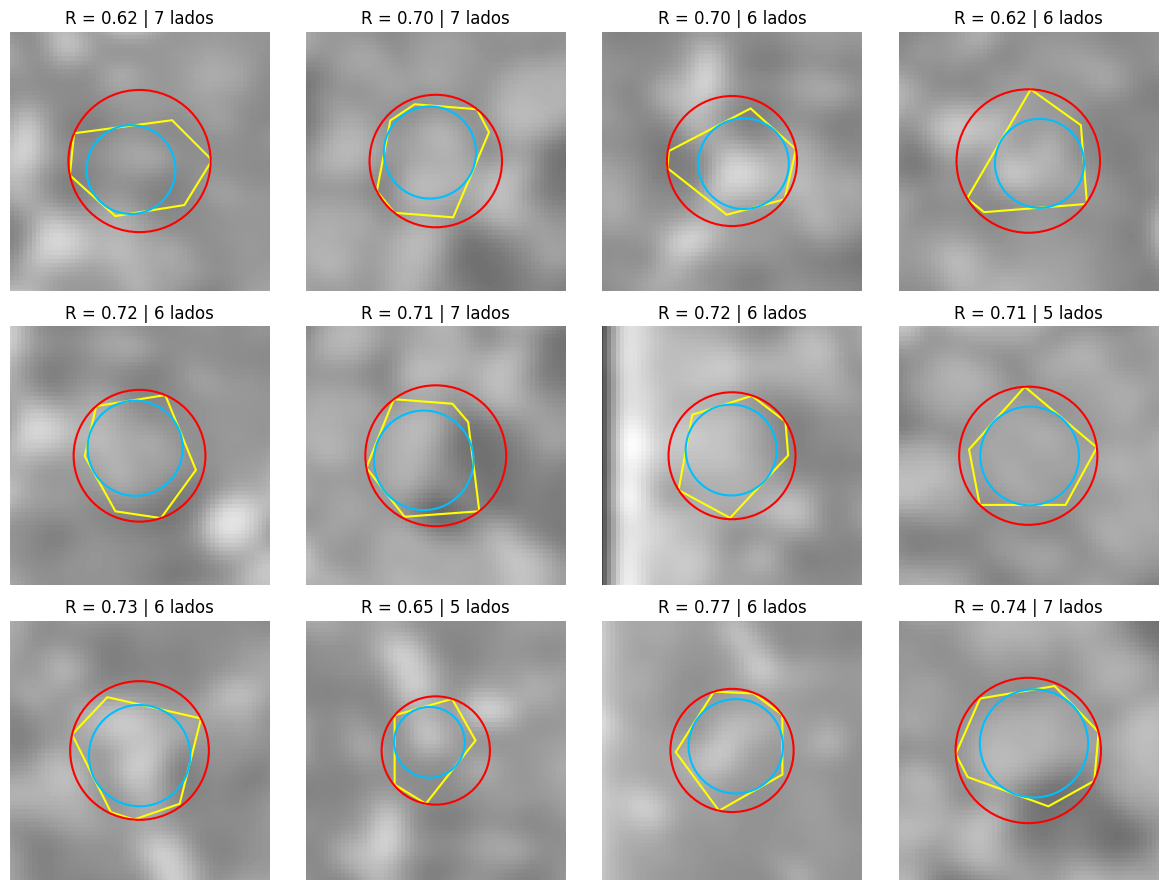

In [ ]:
img, _, _ = abrir_teste(teste.loc[0, 'nome'])
celulas, tab = analisar(img)
esp = espacamento(achar_centros(prever_mapa(img)))

amostra = np.random.default_rng(0).choice(len(celulas), 12, replace=False)
fig, eixos = plt.subplots(3, 4, figsize=(12, 9))
for ax, i in zip(eixos.flat, amostra):
    poli = celulas[i]
    (xi, yi, ri), (xo, yo, ro) = medir_poligono(poli)
    ax.imshow(img, cmap='gray')
    ax.fill(poli[:, 0], poli[:, 1], fill=False, edgecolor='yellow', lw=1.5)
    ax.add_patch(plt.Circle((xi, yi), ri, fill=False, color='deepskyblue', lw=1.5))
    ax.add_patch(plt.Circle((xo, yo), ro, fill=False, color='red', lw=1.5))
    ax.set_xlim(xo - 1.6 * esp, xo + 1.6 * esp); ax.set_ylim(yo + 1.6 * esp, yo - 1.6 * esp)
    ax.set_title(f'R = {ri / ro:.2f} | {len(poli)} lados')
    ax.axis('off')
plt.tight_layout()
plt.show()

In [ ]:
todas = []
for nome in teste['nome']:
    img, _, _ = abrir_teste(nome)
    _, tab = analisar(img)
    if len(tab):
        todas.append(tab.assign(imagem=nome))

por_celula = pd.concat(todas, ignore_index=True)
R_LIM = por_celula['R'].quantile(0.25)
por_celula['classe'] = np.where(por_celula['R'] >= R_LIM, 'regular', 'irregular')
print('R_LIM =', round(R_LIM, 3))

por_imagem = por_celula.groupby('imagem').agg(
    celulas=('R', 'size'),
    R_medio=('R', 'mean'),
    hexagonalidade=('lados', lambda s: (s == 6).mean() * 100),
    irregulares=('classe', lambda s: (s == 'irregular').mean() * 100),
).round(2)

por_celula.to_csv(RESULTADOS / 'por_celula.csv', index=False)
por_imagem.to_csv(RESULTADOS / 'por_imagem.csv')
display(por_imagem.describe().round(2))

R_LIM = 0.698


,celulas,R_medio,hexagonalidade,irregulares
count,48.00,48.00,48.00,48.00
mean,142.29,0.72,54.26,31.58
std,85.43,0.03,8.13,17.39
min,9.00,0.64,33.33,8.96
25%,64.25,0.71,50.00,18.62
50%,135.00,0.73,55.56,28.80
75%,210.00,0.74,59.60,40.59
max,297.00,0.76,67.38,88.89


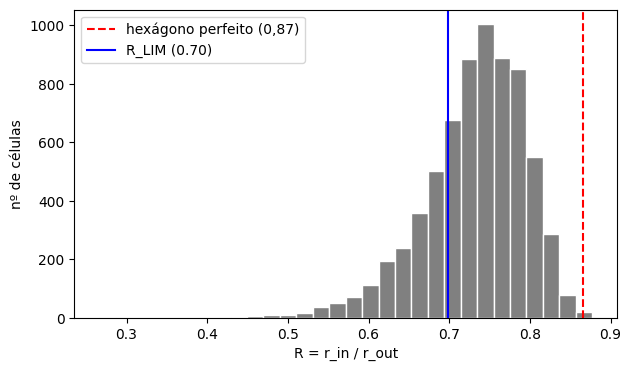

In [ ]:
plt.figure(figsize=(7, 4))
plt.hist(por_celula['R'], bins=30, color='gray', edgecolor='white')
plt.axvline(np.cos(np.pi / 6), color='red', ls='--', label='hexágono perfeito (0,87)')
plt.axvline(R_LIM, color='blue', ls='-', label=f'R_LIM ({R_LIM:.2f})')
plt.xlabel('R = r_in / r_out'); plt.ylabel('nº de células'); plt.legend()
plt.show()

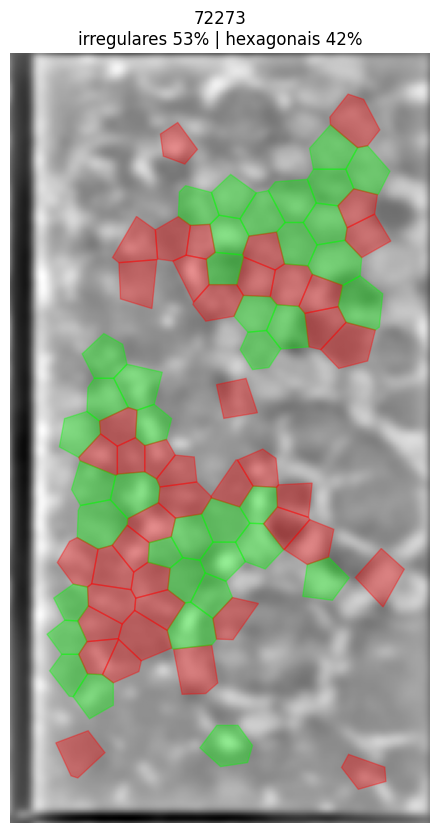

In [ ]:
def mostrar_classificacao(img, celulas, tab, titulo, ax):
    ax.imshow(img, cmap='gray')
    for poli, r in zip(celulas, tab['R']):
        cor = 'lime' if r >= R_LIM else 'red'
        ax.fill(poli[:, 0], poli[:, 1], color=cor, alpha=0.35, edgecolor=cor, lw=1)
    ax.set_title(f'{titulo}\nirregulares {(tab.R < R_LIM).mean():.0%} | hexagonais {(tab.lados == 6).mean():.0%}')
    ax.axis('off')

nome = teste.loc[0, 'nome']
img, _, _ = abrir_teste(nome)
celulas, tab = analisar(img)
fig, ax = plt.subplots(figsize=(6, 10))
mostrar_classificacao(img, celulas, tab, nome, ax)
plt.show()

In [ ]:
from google.colab import files

NOVAS = Path('/content/novas')
NOVAS.mkdir(exist_ok=True)
for nome_arq, conteudo in files.upload().items():
    (NOVAS / nome_arq).write_bytes(conteudo)

Saving endo2.jpeg to endo2.jpeg
Saving endo1.jpg to endo1.jpg


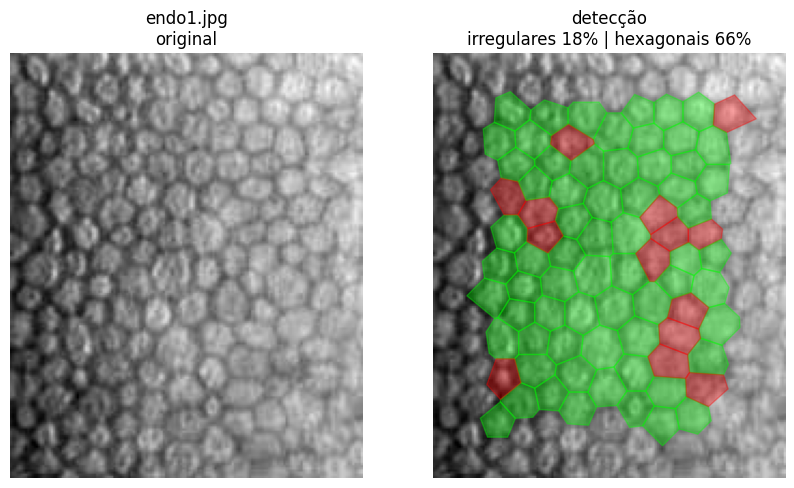

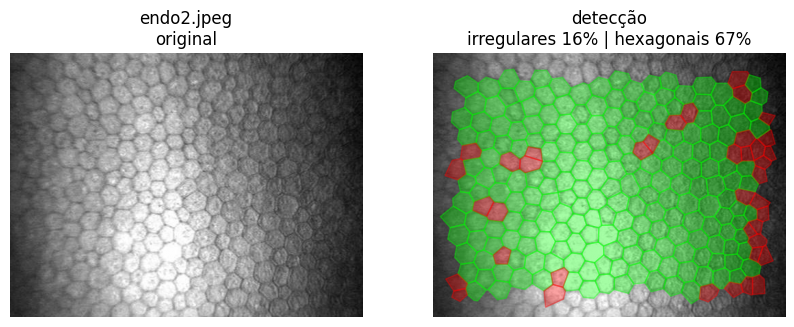

In [ ]:
def fourier_passa_banda(img, esp):
    h, w = img.shape
    F = np.fft.fftshift(np.fft.fft2(img.astype(float)))
    yy, xx = np.ogrid[:h, :w]
    r = np.hypot((yy - h / 2) / h, (xx - w / 2) / w)
    f0 = 1 / esp
    filtro = (1 - np.exp(-(r / (0.5 * f0)) ** 2)) * np.exp(-(r / (2 * f0)) ** 2)
    out = np.real(np.fft.ifft2(np.fft.ifftshift(F * filtro)))
    return cv2.normalize(out, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

ESP_PADRAO = divisao['espacamento'].median()

for caminho in sorted(NOVAS.glob('*')):
    original = cv2.imread(str(caminho), cv2.IMREAD_GRAYSCALE)
    celulas, tab = analisar(fourier_passa_banda(original, ESP_PADRAO))
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 9))
    ax1.imshow(original, cmap='gray'); ax1.set_title(f'{caminho.name}\noriginal'); ax1.axis('off')
    mostrar_classificacao(original, celulas, tab, 'detecção', ax2)
    plt.show()